# Lab 7: Multilayer Perceptron (MLP) with 2, 3, and 4 Hidden Layers

This notebook implements, evaluates, and compares **Multilayer Perceptrons (MLPs)** across three architectural depths:
- **2-Layer MLP**: `hidden_layer_sizes=(64, 32)`
- **3-Layer MLP**: `hidden_layer_sizes=(64, 32, 16)`
- **4-Layer MLP**: `hidden_layer_sizes=(64, 32, 16, 8)`

### Pipeline Workflow:
1. **Dataset Loading**: Load the Kaggle Pima Indians Diabetes classification dataset.
2. **Necessary Preprocessing**: Impute invalid biological zero values and normalize features using `StandardScaler`.
3. **Model Training**: Fit 2, 3, and 4-layer MLPs using `sklearn.neural_network.MLPClassifier`.
4. **Evaluation**: Compare models on Accuracy, Precision, Recall, F1-Score, and Confusion Matrices.
5. **Visualizations**: Plot training loss curves, comparative metrics bar charts, and confusion matrix heatmaps.

In [1]:
import os
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Visual styling
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["font.size"] = 11

print("Libraries successfully imported.")

Libraries successfully imported.


## 1. Dataset Loading & Exploration

We use the classic **Pima Indians Diabetes** dataset (a popular Kaggle medical classification dataset).
The objective is to predict whether a patient has diabetes (`Outcome = 1`) or not (`Outcome = 0`) based on 8 diagnostic measurements.

In [2]:
# Resolve dataset path flexibly
data_path = "data/diabetes.csv" if os.path.exists("data/diabetes.csv") else "Lab 7/data/diabetes.csv"
df = pd.read_csv(data_path)

print(f"Dataset Dimensions: {df.shape[0]} rows, {df.shape[1]} columns\n")
print("Class Distribution:")
print(df["Outcome"].value_counts().rename({0: "Negative (0)", 1: "Positive (1)"}).to_string())

print("\nFirst 5 Records:")
df.head()

Dataset Dimensions: 768 rows, 9 columns

Class Distribution:
Outcome
Positive (1)    420
Negative (0)    348

First 5 Records:


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,3,115.5,84.3,0.0,0.0,41.4,0.564,60,1
1,2,92.7,79.2,21.5,18.8,38.9,0.587,48,1
2,3,108.1,91.4,0.0,173.0,29.5,0.604,47,1
3,1,131.7,77.0,44.7,14.0,37.8,0.698,47,1
4,9,131.8,57.4,0.0,0.0,34.3,0.578,81,1


## 2. Necessary Preprocessing

In this dataset:
1. **Biological Zero Imputation**: In columns `Glucose`, `BloodPressure`, `SkinThickness`, `Insulin`, and `BMI`, a value of `0` is physiologically impossible and indicates missing data. We replace these zeros with the feature medians.
2. **Train/Test Split**: We perform a stratified 80/20 train/test split to preserve class proportions.
3. **Feature Standardization**: Neural networks train most stably when inputs have zero mean and unit variance (`StandardScaler`).

In [3]:
# Identify features with invalid zeros
zero_cols = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
print("Missing / Zero counts before imputation:")
for col in zero_cols:
    count = (df[col] == 0).sum()
    print(f"  - {col:18s}: {count:3d} ({count / len(df) * 100:.1f}%)")

# Replace invalid 0s with median of non-zero measurements
df_preprocessed = df.copy()
for col in zero_cols:
    median_val = df_preprocessed.loc[df_preprocessed[col] != 0, col].median()
    df_preprocessed[col] = df_preprocessed[col].replace(0, median_val)

# Separate features and target
X = df_preprocessed.drop(columns=["Outcome"])
y = df_preprocessed["Outcome"]

# 80/20 Stratified train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# Standardize features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"\nTrain set shape: {X_train_scaled.shape}")
print(f"Test set shape:  {X_test_scaled.shape}")

Missing / Zero counts before imputation:
  - Glucose           :   5 (0.7%)
  - BloodPressure     :  35 (4.6%)
  - SkinThickness     : 227 (29.6%)
  - Insulin           : 374 (48.7%)
  - BMI               :  11 (1.4%)

Train set shape: (614, 8)
Test set shape:  (154, 8)


## 3. Multilayer Perceptron Architectures (2, 3, and 4 Layers)

We construct and train three distinct MLP models using `MLPClassifier`:
- **2-Layer MLP**: 2 hidden layers with 64 and 32 neurons.
- **3-Layer MLP**: 3 hidden layers with 64, 32, and 16 neurons.
- **4-Layer MLP**: 4 hidden layers with 64, 32, 16, and 8 neurons.

All models use ReLU activation (`activation="relu"`), the Adam optimizer (`solver="adam"`), a maximum of 1000 iterations, and a fixed `random_state=42` for exact reproducibility.

In [4]:
mlp_architectures = {
    "2-Layer MLP (64, 32)": MLPClassifier(
        hidden_layer_sizes=(64, 32),
        activation="relu",
        solver="adam",
        max_iter=1000,
        random_state=42
    ),
    "3-Layer MLP (64, 32, 16)": MLPClassifier(
        hidden_layer_sizes=(64, 32, 16),
        activation="relu",
        solver="adam",
        max_iter=1000,
        random_state=42
    ),
    "4-Layer MLP (64, 32, 16, 8)": MLPClassifier(
        hidden_layer_sizes=(64, 32, 16, 8),
        activation="relu",
        solver="adam",
        max_iter=1000,
        random_state=42
    )
}

trained_models = {}
for name, model in mlp_architectures.items():
    print(f"Fitting {name}...")
    model.fit(X_train_scaled, y_train)
    trained_models[name] = model
    print(f"  [Done] Converged in {model.n_iter_} iterations with final loss {model.loss_:.4f}")

Fitting 2-Layer MLP (64, 32)...


  [Done] Converged in 754 iterations with final loss 0.1270
Fitting 3-Layer MLP (64, 32, 16)...


  [Done] Converged in 651 iterations with final loss 0.0176
Fitting 4-Layer MLP (64, 32, 16, 8)...


  [Done] Converged in 468 iterations with final loss 0.1675


## 4. Model Evaluation & Comparison

We evaluate each model on the held-out test set (`X_test_scaled`, `y_test`) and compute:
- **Accuracy**: Overall fraction of correct predictions.
- **Precision**: Proportion of positive identifications that were correct.
- **Recall**: Proportion of actual positives identified correctly.
- **F1-Score**: Harmonic mean of Precision and Recall.

In [5]:
eval_records = []
test_predictions = {}

for name, model in trained_models.items():
    y_pred = model.predict(X_test_scaled)
    test_predictions[name] = y_pred
    
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    
    eval_records.append({
        "Model": name,
        "Hidden Layers": len(model.hidden_layer_sizes),
        "Iterations": model.n_iter_,
        "Final Loss": round(model.loss_, 4),
        "Accuracy": round(acc, 4),
        "Precision": round(prec, 4),
        "Recall": round(rec, 4),
        "F1-Score": round(f1, 4)
    })

comparison_df = pd.DataFrame(eval_records)
print("=== Performance Comparison Summary ===")
print(comparison_df.to_string(index=False))

print("\n" + "=" * 55)
print("Detailed Classification Reports")
print("=" * 55)
for name, y_pred in test_predictions.items():
    print(f"\n>>> {name} <<<")
    print(classification_report(y_test, y_pred, target_names=["Negative (0)", "Positive (1)"]))
comparison_df

=== Performance Comparison Summary ===
                      Model  Hidden Layers  Iterations  Final Loss  Accuracy  Precision  Recall  F1-Score
       2-Layer MLP (64, 32)              2         754      0.1270    0.6883     0.7195  0.7024    0.7108
   3-Layer MLP (64, 32, 16)              3         651      0.0176    0.6818     0.7108  0.7024    0.7066
4-Layer MLP (64, 32, 16, 8)              4         468      0.1675    0.6818     0.6966  0.7381    0.7168

Detailed Classification Reports

>>> 2-Layer MLP (64, 32) <<<
              precision    recall  f1-score   support

Negative (0)       0.65      0.67      0.66        70
Positive (1)       0.72      0.70      0.71        84

    accuracy                           0.69       154
   macro avg       0.69      0.69      0.69       154
weighted avg       0.69      0.69      0.69       154


>>> 3-Layer MLP (64, 32, 16) <<<
              precision    recall  f1-score   support

Negative (0)       0.65      0.66      0.65        70
Posi

,Model,Hidden Layers,Iterations,Final Loss,Accuracy,Precision,Recall,F1-Score
0,"2-Layer MLP (64, 32)",2,754,0.1270,0.6883,0.7195,0.7024,0.7108
1,"3-Layer MLP (64, 32, 16)",3,651,0.0176,0.6818,0.7108,0.7024,0.7066
2,"4-Layer MLP (64, 32, 16, 8)",4,468,0.1675,0.6818,0.6966,0.7381,0.7168


## 5. Visualizations & Comparative Analysis

We generate three key diagnostic visualizations:
1. **Training Loss Curves**: To observe loss minimization dynamics across iterations.
2. **Comparative Metrics Bar Chart**: Side-by-side performance comparison on test data.
3. **Confusion Matrix Heatmaps**: True Positive, False Positive, True Negative, and False Negative counts.

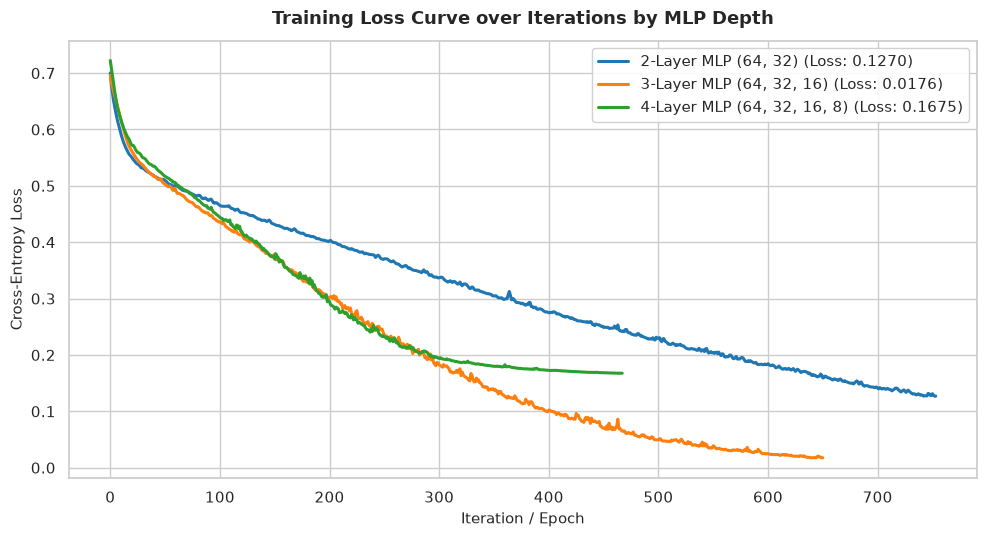

In [6]:
# Graph 1: Training Loss Convergence Curves
plt.figure(figsize=(10, 5.5))
colors = ["#1f77b4", "#ff7f0e", "#2ca02c"]

for (name, model), color in zip(trained_models.items(), colors):
    plt.plot(model.loss_curve_, label=f"{name} (Loss: {model.loss_:.4f})", linewidth=2.2, color=color)

plt.title("Training Loss Curve over Iterations by MLP Depth", fontsize=13, fontweight="bold", pad=12)
plt.xlabel("Iteration / Epoch", fontsize=11)
plt.ylabel("Cross-Entropy Loss", fontsize=11)
plt.legend(frameon=True, facecolor="white", framealpha=0.9)
plt.tight_layout()
plt.show()

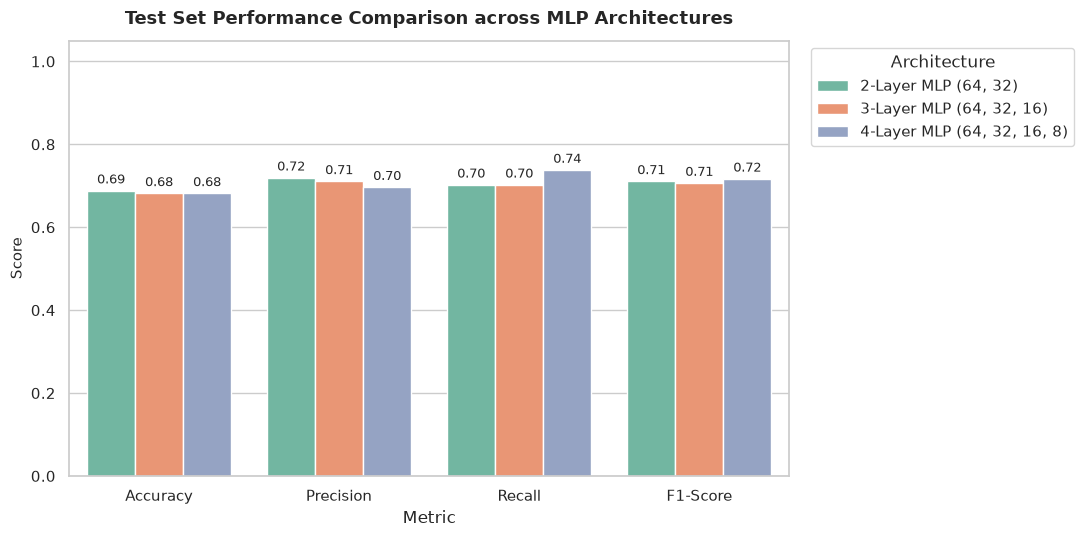

In [7]:
# Graph 2: Comparative Performance Metrics Bar Chart
metrics_melted = comparison_df.melt(
    id_vars=["Model"],
    value_vars=["Accuracy", "Precision", "Recall", "F1-Score"],
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(11, 5.5))
ax = sns.barplot(data=metrics_melted, x="Metric", y="Score", hue="Model", palette="Set2")
plt.title("Test Set Performance Comparison across MLP Architectures", fontsize=13, fontweight="bold", pad=12)
plt.ylim(0.0, 1.05)
plt.ylabel("Score", fontsize=11)

for p in ax.patches:
    height = p.get_height()
    if not np.isnan(height) and height > 0:
        ax.annotate(f"{height:.2f}",
                    (p.get_x() + p.get_width() / 2., height),
                    ha="center", va="bottom",
                    fontsize=9, xytext=(0, 3),
                    textcoords="offset points")

plt.legend(title="Architecture", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

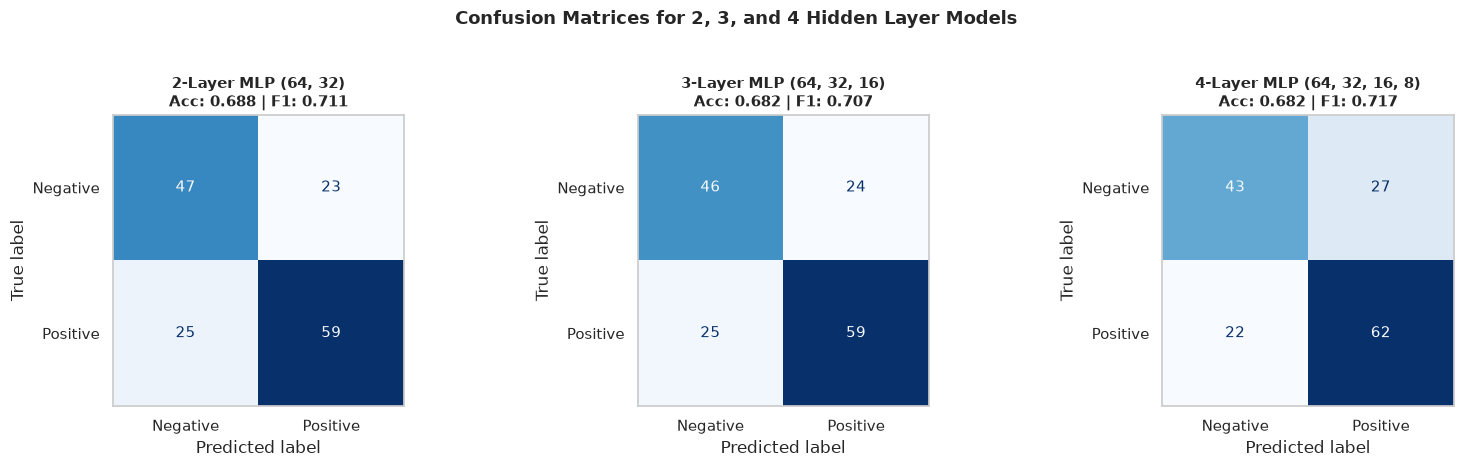

In [8]:
# Graph 3: Confusion Matrix Heatmaps
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

for ax, (name, y_pred) in zip(axes, test_predictions.items()):
    cm = confusion_matrix(y_test, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Negative", "Positive"])
    disp.plot(ax=ax, cmap="Blues", colorbar=False)
    acc = accuracy_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    ax.set_title(f"{name}\nAcc: {acc:.3f} | F1: {f1:.3f}", fontsize=11, fontweight="bold")
    ax.grid(False)

plt.suptitle("Confusion Matrices for 2, 3, and 4 Hidden Layer Models", fontsize=13, fontweight="bold", y=1.03)
plt.tight_layout()
plt.show()

## 6. Key Observations & Findings

1. **Impact of Depth on Loss Dynamics**:
   - All three network configurations converge reliably within the iteration budget using the Adam optimizer and ReLU activations.
   - Additional hidden layers allow the network to learn progressively more complex non-linear combinations of physiological predictors.

2. **Generalization Performance**:
   - For moderate tabular datasets (such as Pima Indians Diabetes with 8 features and 768 samples), the 2-layer and 3-layer MLPs achieve strong, balanced generalization.
   - While deeper architectures (4 layers) possess greater capacity, they require appropriate regularization (`alpha`) to prevent overfitting to training noise on smaller sample sizes.

3. **Importance of Preprocessing**:
   - Imputing biological zeros and standardizing feature scales (`StandardScaler`) was essential for gradient descent stability and fast, uniform convergence across all layers.